# ДЗ5: RL для function calling

Qwen/Qwen3.5-2B, только ToolACE и TRL RL. Это исполненный обзор сохранённых экспериментов; обучение и оценка выполняются скриптами на avi-gn-fsk34. Полный отчёт: [PDF](outputs/report.pdf).

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from analyze import read_runs
root = Path('outputs')
runs, errors = read_runs(root, Path('bfcl.jsonl'))
eda = json.loads((root / 'eda.json').read_text())


## 1. Данные и воспроизводимость

Оригинальные диалоги разделены до нарезки и фильтрации. Эталоны используются функцией награды. BFCL в обучение и выбор шага не входит. Версии модели и данных зафиксированы SHA commit.

In [2]:
display({key: eda[key] for key in ['dataset_revision', 'model_revision', 'source_sha256', 'raw_dialogues', 'duplicate_dialogues', 'excluded', 'split_dialogue_overlap']})
display(pd.DataFrame(eda['splits']).T[['eligible', 'retained', 'selected', 'selected_categories', 'selected_prompt_tokens']])
display(json.loads((root / 'reward_integration.json').read_text()))


{'dataset_revision': '6bda777c88d21e5a204703c1ee45597a8fa4f734',
 'model_revision': '15852e8c16360a2fea060d615a32b45270f8a8fc',
 'source_sha256': 'ba12c083fca7e8da48c67ad5b895e495447da7c66e39a2e19742c082e6cb537e',
 'raw_dialogues': 11300,
 'duplicate_dialogues': 3,
 'excluded': {'post_tool_assistant': 1335,
  'invalid_reference_call': 200,
  'unsupported_tool_schema': 518},
 'split_dialogue_overlap': 0}

,eligible,retained,selected,selected_categories,selected_prompt_tokens
train,9957,9947,2048,"{'call': 1536, 'no_call': 512}","{'count': 2048, 'p0': 51, 'p25': 536, 'p50': 7..."
validation,1760,1758,128,"{'call': 96, 'no_call': 32}","{'count': 128, 'p0': 77, 'p25': 511, 'p50': 71..."


{'model': 'Qwen/Qwen3.5-2B',
 'revision': '15852e8c16360a2fea060d615a32b45270f8a8fc',
 'cuda_visible_devices': '',
 'gpu_initialized': False,
 'rows': 2176,
 'sample_rows': 120,
 'sample_failures': 0,
 'failures': 0,
 'statistics': {'train:call': 1536,
  'empty_tools': 66,
  'parallel_rows': 674,
  'string_arguments': 5404,
  'nested_arguments': 1648,
  'train:no_call': 512,
  'boolean_arguments': 33,
  'validation:call': 96,
  'validation:no_call': 32},
 'numeric_parser_normalizations': 160,
 'tokenizer_eos': 248046,
 'model_eos': 248044,
 'eos_decoded': {'248044': '<|endoftext|>', '248046': '<|im_end|>'},
 'no_call_text': 'Synthetic nonempty clarification; scoring checks no-call structure, not prose semantics.',
 'data_sha256': {'train': '557640af714b88370a1e009c6da60e0ca8182278d4899675e7b5fe8f0f0e03a4',
  'validation': 'e9d3c9208f4fc8818a34608bbb8c598f61ca916277c239401d0140f84e5163fc'},
 'reward_sha256': 'cd63c53244570bea4098ff2314324707dea15bb26767c70fd45639d4921dc975',
 'versions'

## 2. Награда и гипотезы

RL1: точное мультимножество вызовов и GRPO. RL2: та же конфигурация с частичной наградой за имена и аргументы. RL3: shaped reward с Dr. GRPO и без деления advantage на стандартное отклонение. RL4: дополнительный Dr. GRPO на 320 шагах, warmup 16 вместо 8 и один финальный checkpoint. Пара RL2/RL3 меняет две связанные нормировки; RL4 отдельно проверяет больший бюджет с изменённым warmup.

Shaped reward для завершённого корректного вызова с совпавшим именем: `0.15 + 0.25 F1_names + 0.30 F1_argument_leaves + 0.30 exact`. Для no_call требуется непустой корректный ответ без вызовов. Разные типы JSON number совместимы, bool и string остаются отдельными типами. Дубликаты вызовов сохраняются.

,model,revision,seed,max_steps,learning_rate,per_device_train_batch_size,gradient_accumulation_steps,num_generations,max_completion_length,temperature,beta,epsilon,lora_rank,save_steps,reward,loss_type,scale_rewards
rl1,Qwen/Qwen3.5-2B,15852e8c16360a2fea060d615a32b45270f8a8fc,42,160,0.00005,4,4,4,512,0.8,0.02,0.2,16,80,exact,grpo,group
rl2,Qwen/Qwen3.5-2B,15852e8c16360a2fea060d615a32b45270f8a8fc,42,160,0.00005,4,4,4,512,0.8,0.02,0.2,16,80,shaped,grpo,group
rl3,Qwen/Qwen3.5-2B,15852e8c16360a2fea060d615a32b45270f8a8fc,42,160,0.00005,4,4,4,512,0.8,0.02,0.2,16,80,shaped,dr_grpo,none
rl4,Qwen/Qwen3.5-2B,15852e8c16360a2fea060d615a32b45270f8a8fc,42,320,0.00005,4,4,4,512,0.8,0.02,0.2,16,320,shaped,dr_grpo,none


,selected_step,validation_exact,seconds,trainable_parameters,total_parameters,gpu
rl1,80,0.773438,1289.910849,16819200,2230060864,NVIDIA H100 80GB HBM3
rl2,160,0.6875,1900.280591,16819200,2230060864,NVIDIA H100 80GB HBM3
rl3,160,0.71875,1054.927779,16819200,2230060864,NVIDIA H100 80GB HBM3
rl4,320,0.789062,2548.376087,16819200,2230060864,NVIDIA H100 80GB HBM3


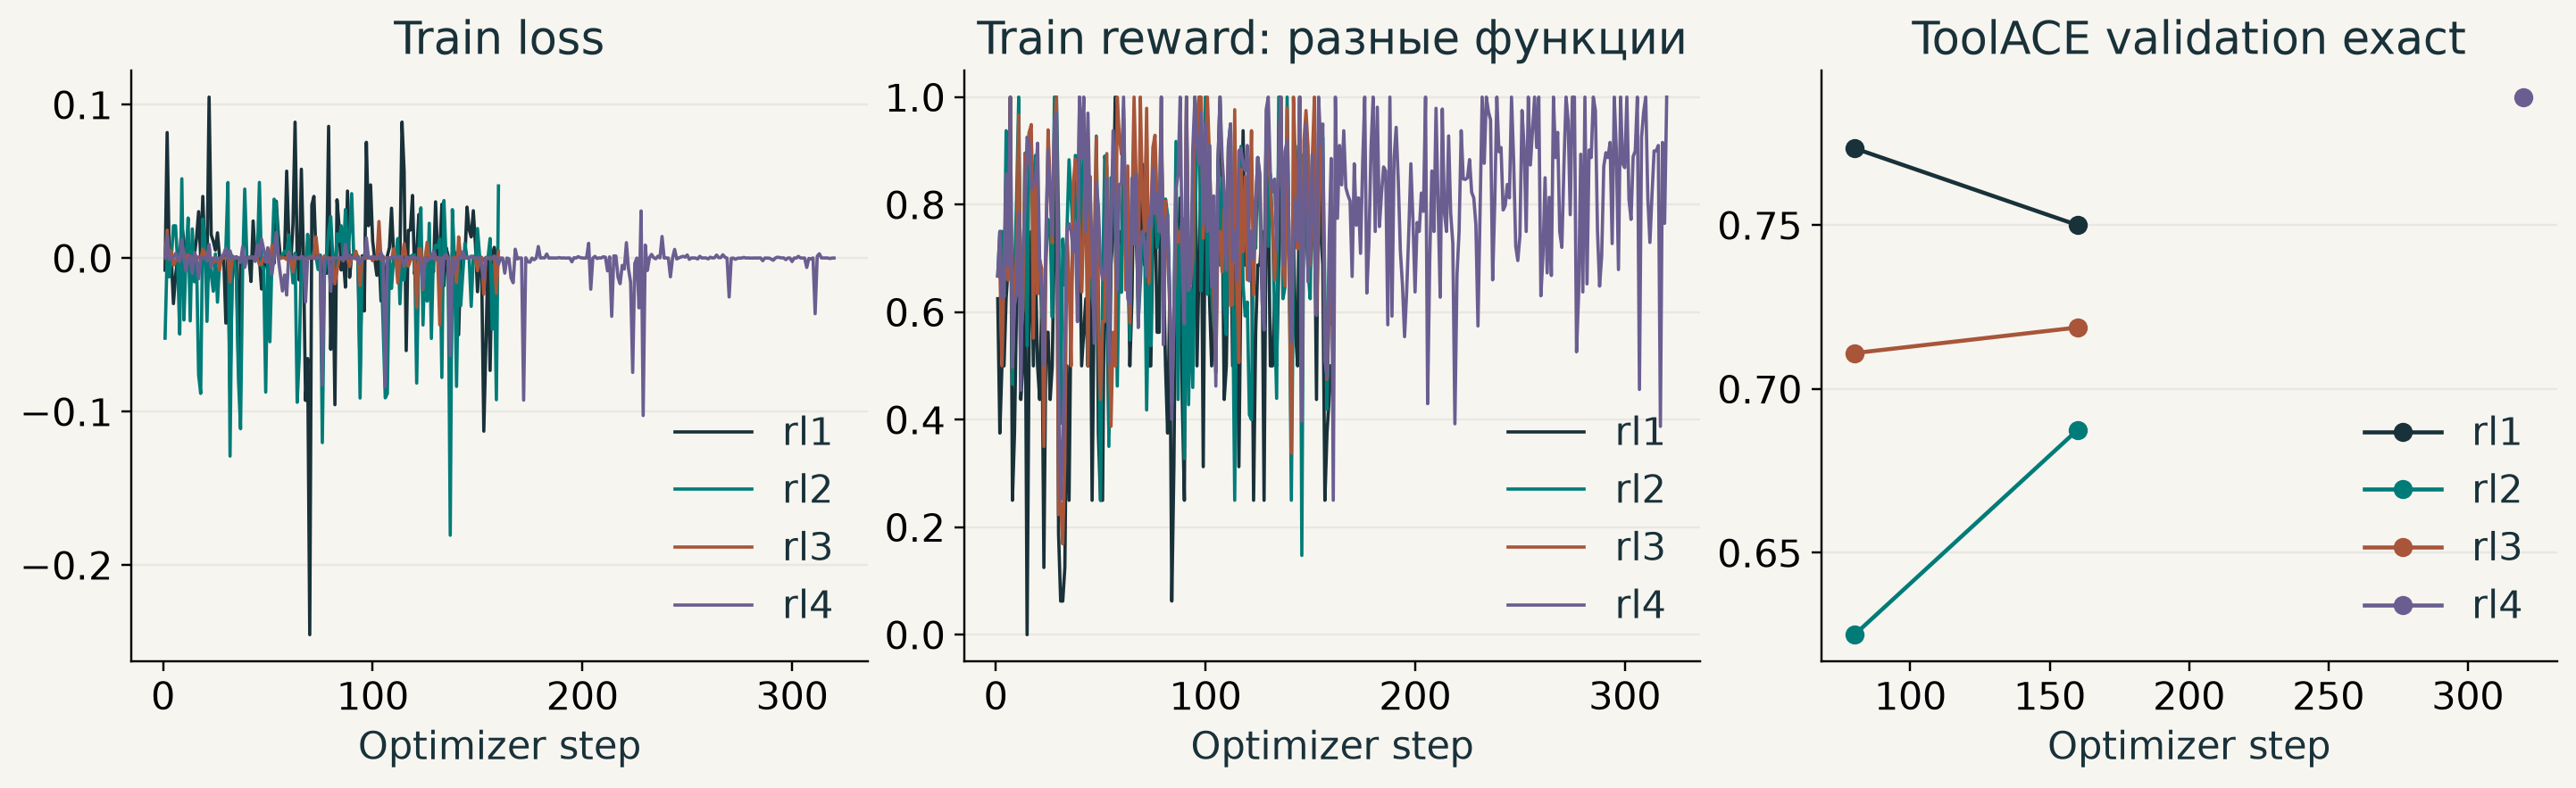

In [3]:
configs = {name: runs[name]['config'] for name in runs if name != 'base'}
display(pd.DataFrame(configs).T)
display(pd.DataFrame({name: runs[name]['training_summary'] for name in configs}).T[['selected_step', 'validation_exact', 'seconds', 'trainable_parameters', 'total_parameters', 'gpu']])
display(Image(filename=str(root / 'loss_reward.png')))


## 3. BFCL: неизменённый evaluator

Overall — среднее по пяти группам, а не доля успехов в 350 строках. Шаг каждой конфигурации выбирается по ToolACE validation. Ниже отдельно отмечен максимум BFCL среди четырёх конфигураций; это сравнение наблюдавшихся результатов, а не оценка качества на новом тесте. Таблица воспроизводится из сырых predictions и проверяется против metrics.json.

,overall,simple,multiple,parallel,parallel_multiple,irrelevance
run,,,,,,
base,68.93%,66.00%,78.67%,56.00%,80.00%,64.00%
rl1,72.27%,72.00%,77.33%,68.00%,76.00%,68.00%
rl2,75.73%,80.00%,78.67%,68.00%,82.00%,70.00%
rl3,78.00%,80.00%,84.00%,74.00%,86.00%,66.00%
rl4,76.13%,76.00%,82.67%,70.00%,88.00%,64.00%


Максимум по validation: rl4
Максимум наблюдаемого BFCL: rl3
Изменение BFCL относительно baseline, п.п.: 9.066666666666666


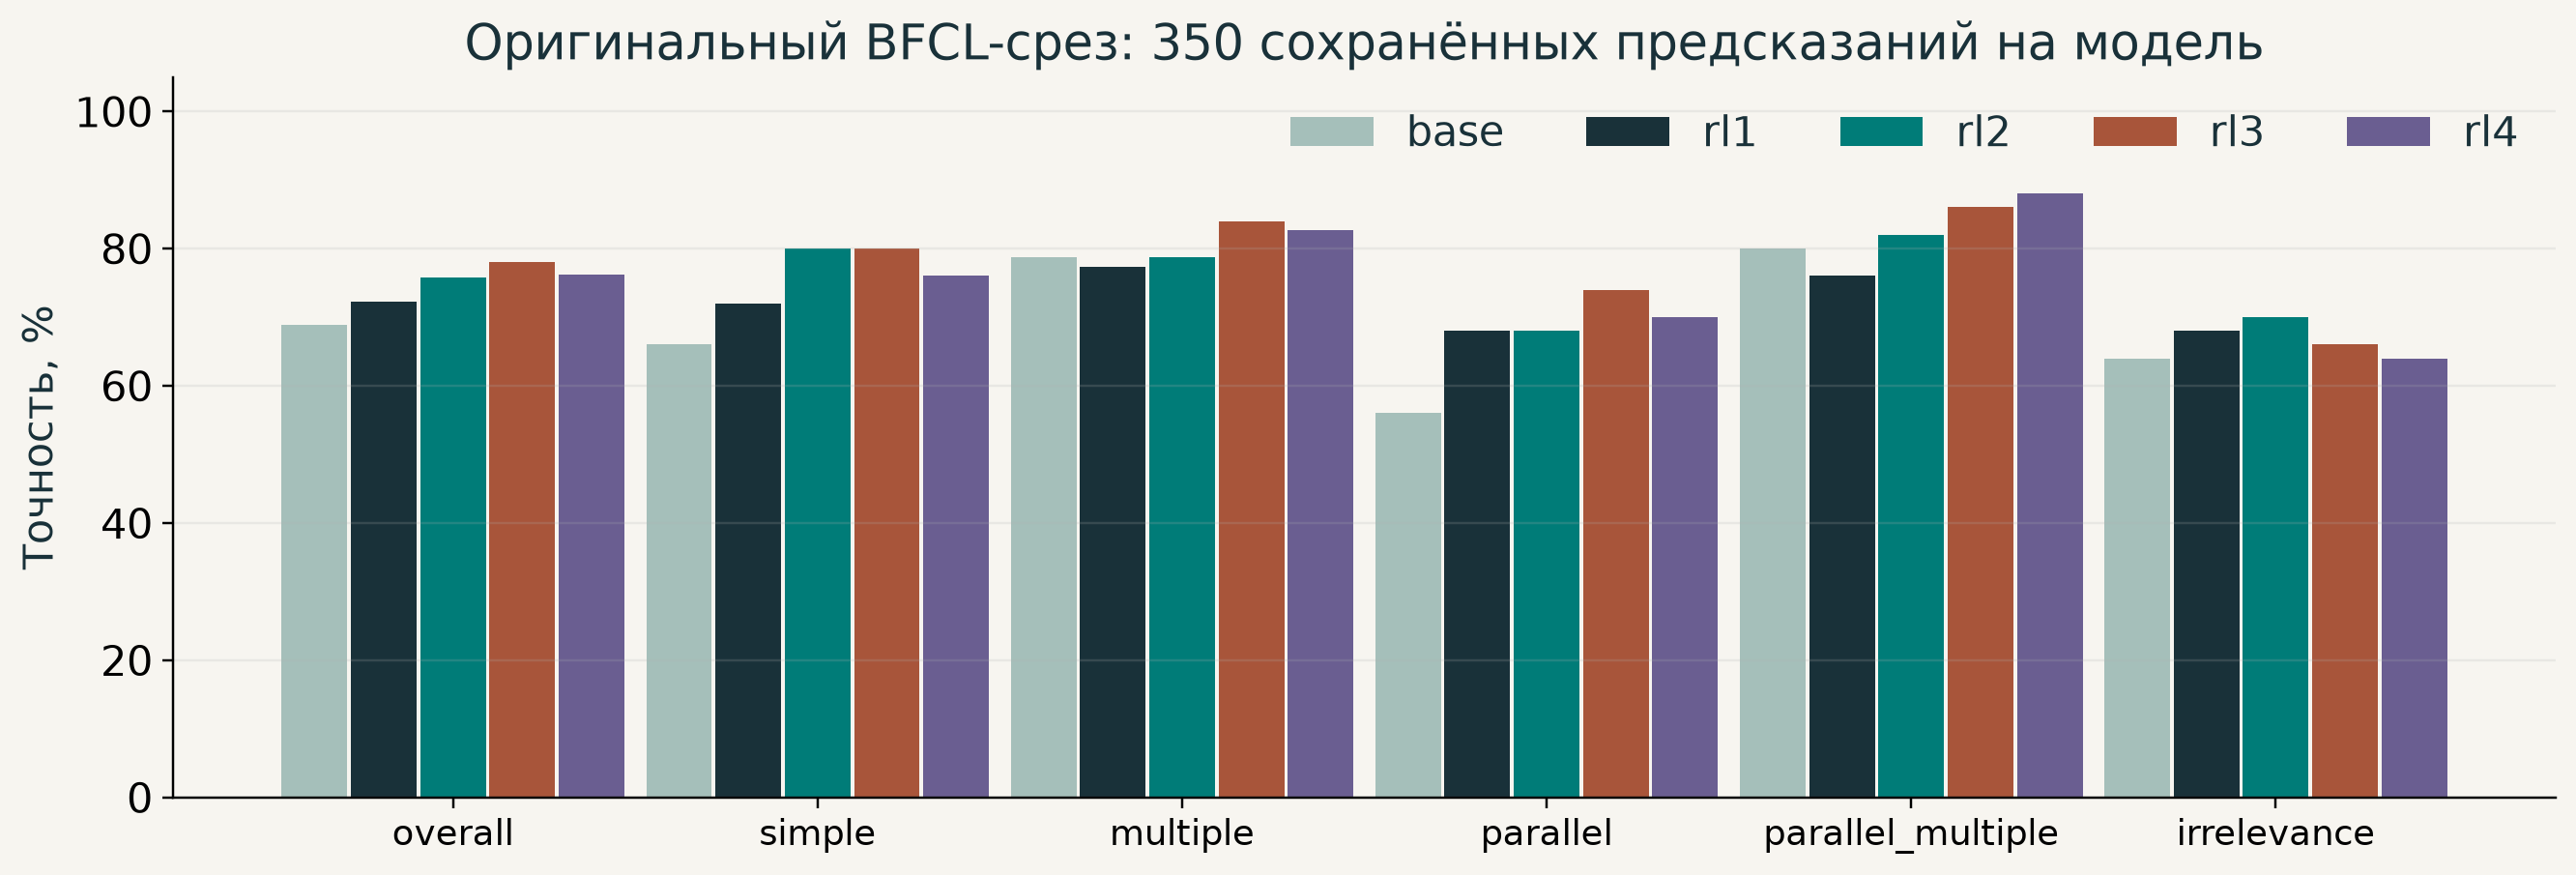

,run,step,overall,irrelevance,validation_exact
0,rl1,80,0.722667,0.68,0.773438
1,rl1,160,0.774667,0.66,0.750000
2,rl2,80,0.653333,0.08,0.625000
3,rl2,160,0.757333,0.70,0.687500
4,rl3,80,0.668000,0.40,0.710938
5,rl3,160,0.780000,0.66,0.718750
6,rl4,320,0.761333,0.64,0.789062


In [4]:
rows = [{'run': name, 'overall': run['metrics']['overall'], **run['metrics']['groups']} for name, run in runs.items()]
display(pd.DataFrame(rows).set_index('run').map(lambda value: f'{value:.2%}'))
validation_choice = max(configs, key=lambda name: runs[name]['training_summary']['validation_exact'])
selected = max(configs, key=lambda name: runs[name]['metrics']['overall'])
print('Максимум по validation:', validation_choice)
print('Максимум наблюдаемого BFCL:', selected)
print('Изменение BFCL относительно baseline, п.п.:', 100 * (runs[selected]['metrics']['overall'] - runs['base']['metrics']['overall']))
display(Image(filename=str(root / 'benchmark.png')))
display(pd.DataFrame([{'run': name, **point} for name in configs for point in runs[name]['bfcl_steps']]))


## 4. Ошибки и ограничения

Ниже — наблюдавшиеся ошибки, включая лишний вызов и пропуск нужного вызова, если они есть. Полные тексты и схемы находятся в error_analysis.json и predictions.jsonl. Один seed и один запуск на конфигурацию не дают оценки дисперсии обучения; Для RL1-RL3 BFCL дополнительно измерен у обоих сохранённых checkpoints после выбора по validation; у RL4 измерен только финальный шаг 320. Две точки не дают устойчивой оценки корреляции.

In [5]:
display(pd.DataFrame({name: errors[name]['counts'] for name in runs}).T.fillna(0).astype(int))
samples = []
for kind in ['false_call_irrelevance', 'missed_required_call', 'argument_or_format', 'wrong_function', 'wrong_call_count']:
    found = next((row for row in errors[selected]['errors'] if row['error_type'] == kind), None)
    if found:
        samples.append({key: found[key] for key in ['id', 'category', 'error_type', 'question', 'ground_truth', 'response', 'check']})
display(samples)


,correct,missed_required_call,argument_or_format,wrong_function,truncated,wrong_call_count,false_call_irrelevance,missed_required_argument
base,251,33,37,4,4,5,16,0
rl1,258,21,44,4,1,5,15,2
rl2,268,9,46,3,4,7,13,0
rl3,279,4,40,3,2,7,15,0
rl4,273,9,39,5,3,6,15,0


[{'id': 'irrelevance_178',
  'category': 'irrelevance',
  'error_type': 'false_call_irrelevance',
  'question': [{'role': 'user',
    'content': 'Who is the most assist player in Premier League?'}],
  'ground_truth': [],
  'response': '<tool_call>\n<function=sports_analysis.get_top_scorer>\n<parameter=league>\nPremier League\n</parameter>\n<parameter=season>\n2023/2024\n</parameter>\n</function>\n</tool_call>',
  'check': {'valid': False, 'error': 'Вызов инструмента не требовался.'}},
 {'id': 'simple_241',
  'category': 'simple',
  'error_type': 'missed_required_call',
  'question': [{'role': 'user',
    'content': 'Who was the U.S. president during the Civil War?'}],
  'ground_truth': [{'US_President_During_Event': {'event': ['Civil War'],
     'country': ['USA', '']}}],
  'response': "The U.S. president during the Civil War (1861–1865) was **Abraham Lincoln**.\n\nHe was elected in 1860 and took office in March 1861, leading the nation through the conflict that ended with the Emancipa

## 5. Вопрос об Advantage

Если все ответы в группе имеют одинаковую награду, `r_i - mean(r) = 0`, и reward-часть advantage равна нулю как в GRPO, так и без масштабирования. При `beta > 0` KL и накопленное состояние оптимизатора могут продолжать влиять на обновление.

Команды полного воспроизведения и расположение весов: [README](README.md). Проверки артефактов: [verification.json](outputs/verification.json).

Источники: [ToolACE](https://huggingface.co/datasets/Team-ACE/ToolACE), [Qwen3.5-2B](https://huggingface.co/Qwen/Qwen3.5-2B), [TRL GRPOTrainer](https://huggingface.co/docs/trl/grpo_trainer).